# Package imports

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
from scipy.optimize import LinearConstraint
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt

In [2]:
def SIRS_model(t, x, p):
    S, I, R = x
    β, γ, ν = p

    dS_dt = ν*R - β*S*I
    dI_dt = β*S*I - γ*I
    dR_dt = γ*I - ν*R

    return np.array([dS_dt, dI_dt, dR_dt])

### Simulate ODE Trajectory

In [3]:
β = 1.5
γ = 1
ν = 1/12

p = (β, γ, ν)

tmax = 21
tspan = (0, tmax)
num_observations = 32
obs_times = np.linspace(tspan[0], tspan[1], num_observations)
i0 = 1e-3
x0 = (1 - i0, i0, 0)
parameterized_model = lambda t, x: SIRS_model(t, x, p)
sol = solve_ivp(parameterized_model, tspan, x0, method='RK45', t_eval=obs_times)

### Add multiplicative noise

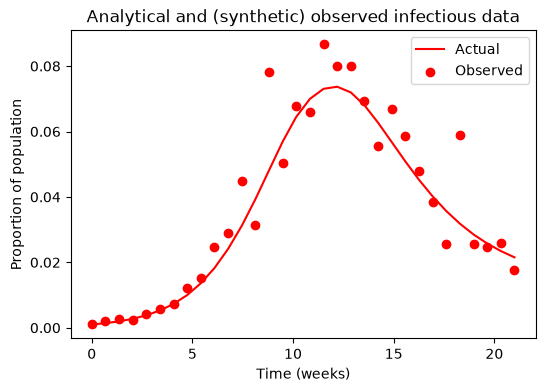

In [4]:
std_dev = 0.25 # 10% noise

observations = sol.y[1]*np.exp(np.random.normal(0, std_dev, num_observations))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")

ax.legend()
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Proportion of population")

plt.title("Analytical and (synthetic) observed infectious data")

plt.savefig("Figures/SIRS_actual_vs_observed_data.pdf", dpi=300)

plt.show()

In [414]:
# Calculates the L2 log difference between two arrays
def log_loss_functional(arr1, arr2):
    # Ensure that arr1 and arr2 have the same shape
    if np.shape(arr1) != np.shape(arr2):
        print("Error in loss_functional: arr1 and arr2 must have same shape")
        return -1

    # Convert arrays to numpy arrays if necessary
    if not isinstance(arr1, np.ndarray):
        arr1 = np.array(arr1)
    if not isinstance(arr2, np.ndarray):
        arr2 = np.array(arr2)

    # Ensure that arr1 is nonnegative and arr2 is positive
    arr1 = np.where(arr1 > 0, arr1, 0)
    arr2 = np.where(arr2 > 0, arr2, 1e-64)

    # Calculate arr1 / arr2 elementwise, ensuring all results are positive
    arr1_over_arr2_positive = np.where(arr1 / arr2 > 0, arr1 / arr2, 1e-64) 
    
    # Return the sum-of-squared log distances between arr1 and arr2
    return np.sum(np.pow(np.log(arr1_over_arr2_positive), 2))




# # Calculates the L2 log difference between two arrays
# def linear_loss_functional(arr1, arr2):
#     # Ensure that arr1 and arr2 have the same shape
#     if np.shape(arr1) != np.shape(arr2):
#         print("Error in loss_functional: arr1 and arr2 must have same shape")
#         return -1
#
#     # Convert arrays to numpy arrays if necessary
#     if not isinstance(arr1, np.ndarray):
#         arr1 = np.array(arr1)
#     if not isinstance(arr2, np.ndarray):
#         arr2 = np.array(arr2)
#
#     # Return the sum-of-squared log distances between arr1 and arr2
#     return np.sum(np.pow(arr1 - arr2, 2))




# Calculates the L2 difference between observations and the model with parameters p
def calculate_model_loss(obs_times, observations, model, x0, p, observed_variables=None):
    cumulative_loss = 0

    # If observed variables are not given, return
    if observed_variables is None:
        print("Error: the indices of the observed components must be provided.")
        return -1

    observations = np.array(observations)
    observed_variables = np.array(observed_variables)

    # If observations is a 1D array, turn it into a 2D array with one row
    if observations.ndim == 1:
        observations = observations.reshape(1, -1)

    if observed_variables.ndim != 2:
        print(f"Error: observed_variables must have two dimensions. observed_variables.ndim = {observed_variables.ndim}")
        return -1

    if observed_variables.shape[0] != observations.shape[0]:
        print("Error: the number of observed variables must match the number of rows in observations")
        print(f"observed_variables.shape[0] = {observed_variables.shape[0]}")
        print(f"observations.shape[0] = {observations.shape[0]}")
        return -1

    parameterized_model = lambda t, x: model(t, x, p)
    tspan = (obs_times[0], obs_times[-1])
    sol = solve_ivp(parameterized_model, tspan, x0, method='RK45', t_eval=obs_times)

    # print([sol.y[i] for i in observed_variables])
    # print(np.array([sol.y[i] for i in observed_variables]))
    # print(np.sum(np.array([sol.y[i] for i in observed_variables]), axis=0))

    for i in range(observed_variables.shape[0]):
        cumulative_loss += log_loss_functional(observations[i], np.sum(np.array([sol.y[j] for j in observed_variables[i]]), axis=0))

    return cumulative_loss




def generate_known_vars_constraint(nvars, known_vars, wiggle_room=0):
    # Don't create a linear constraint if no variables are known
    if known_vars is None:
        return None

    # Ensure that length(known_vars) is equal to the number of variables
    if len(known_vars) != nvars:
        print("Error: length(known_vars) is not equal to the number of variables, defaulting to known_vars = None.")
        return None

    # Find the indices of known variables
    known_var_indices = np.where(np.array(known_vars) != None)[0]

    # If known_vars only contains None, then no variables are known
    if known_var_indices.size == 0:
        return None
    
    # Now known_p contains at least one known parameter, so create the constraint
    constraint_matrix = np.zeros((len(known_var_indices), nvars))
    for i in range(len(known_var_indices)):
        constraint_matrix[i, known_var_indices[i]] = 1

    constraint_values = np.array([known_vars[known_var_indices[i]] for i in range(len(known_var_indices))])
    return LinearConstraint(constraint_matrix, constraint_values*(1 - wiggle_room), constraint_values*(1 + wiggle_room))




# # Optimizes the parameters for <model> given an initial condition <x0>, <obs_times>, and <observations>
# def optimize_parameters(obs_times, observations, model, x0, p_guess, known_p=None, p_bounds=None, tol=1e-8, wiggle_room=1e-8):
#     npars = len(p_guess)
#     known_p_constraint = None # Set by default, will change if known_p is given
#
#     # Set parameter bounds to be large if not given
#     if p_bounds == None:
#         p_bounds = [(0, 1e4) for i in range(npars)]
#
#     known_p_constraint = generate_known_vars_constraint(npars, known_p, wiggle_room=wiggle_room)
#
#     npars = len(p_guess) # Number of parameters
#     initial_guess = p_guess # Initial parameter guess
#     objfun = lambda p: calculate_model_loss(obs_times, observations, model, x0, p) # Objective function
#
#     # Find optimal parameters
#     return minimize(objfun, initial_guess, bounds=p_bounds, tol=tol, constraints=(known_p_constraint))




def optimize_parameters(obs_times, observations, model, x0, p_guess, **kwargs):
    observed_variables = kwargs.get("observed_variables", None)
    known_p = kwargs.get("known_p", None)
    p_bounds = kwargs.get("p_bounds", None)
    tol = kwargs.get("tol", 1e-8)
    wiggle_room = kwargs.get("wiggle_room", 1e-8)

    # Call optimize_ics_and_parameters with x0_guess and known_x0 fixed as x0
    return optimize_ics_and_parameters(obs_times, observations, model, x0, p_guess, observed_variables=observed_variables,
            known_x0=x0, known_p=known_p, x0_bounds=None, p_bounds=p_bounds, tol=tol, wiggle_room=0)





# Optimizes the parameters and initial conditions for <model> given <obs_times> and <observations>
def optimize_ics_and_parameters(obs_times, observations, model, x0_guess, p_guess, **kwargs):
    observed_variables = kwargs.get("observed_variables", None)
    known_x0 = kwargs.get("known_x0", None)
    known_p = kwargs.get("known_p", None)
    x0_bounds = kwargs.get("x0_bounds", None)
    p_bounds = kwargs.get("p_bounds", None)
    tol = kwargs.get("tol", 1e-8)
    wiggle_room = kwargs.get("wiggle_room", 1e-12)

    wiggle_room = 0

    if observed_variables is None:
        print("Error: indeces of observed variables must be provided")
        return -1

    nstates = len(x0_guess) # Number of state variables
    npars = len(p_guess) # Number of parameters
    constraints = []

    # If known_x0 or known_p are None, reallocate them as arrays with entries <None>
    if known_x0 is None:
        known_x0 = np.empty((nstates), dtype=object)
    else:
        known_x0 = np.array(known_x0)
    if known_p is None:
        known_p = np.empty((npars), dtype=object)
    else:
        known_p = np.array(known_p)

    # Set x0 and parameter bounds to [0, Inf) if not given
    if x0_bounds is None:
        x0_bounds = [(0, None) for i in range(nstates)]
    else:
        x0_bounds = np.array(x0_bounds)
    if p_bounds is None:
        p_bounds = [(0, None) for i in range(npars)]
    else:
        p_bounds = np.array(p_bounds)

    # Generate the x0 and p constraints from the provided known values
    known_x0_constraint = generate_known_vars_constraint(nstates, known_x0, wiggle_room=wiggle_room)
    known_p_constraint = generate_known_vars_constraint(npars, known_p, wiggle_room=wiggle_room)

    # Extend the size of the x0 constraint to include p variables
    if known_x0_constraint != None:
        known_x0 = np.array(known_x0)
        A = known_x0_constraint.A
        A = np.hstack((A, np.zeros((A.shape[0], npars))))
        lb = known_x0_constraint.lb
        ub = known_x0_constraint.ub
        constraints.append(LinearConstraint(A, lb, ub))
        x0_guess = np.where(known_x0 != None, known_x0, x0_guess) # Replace guesses with known values

    # Extend the size of the p constraint to include x0 variables
    if known_p_constraint != None:
        known_p = np.array(known_p)
        A = known_p_constraint.A
        A = np.hstack((np.zeros((A.shape[0], nstates)), A))
        lb = known_p_constraint.lb
        ub = known_p_constraint.ub
        constraints.append(LinearConstraint(A, lb, ub))
        p_guess = np.where(known_p != None, known_p, p_guess) # Replace guesses with known values

    # If there is no known_x0 constraint, add a constraint so that the initial pop. size is the same as that guessed
    if known_x0_constraint is None:
        constraint_matrix = np.concatenate((np.ones(nstates), np.zeros(npars))) # e.g. [1 1 1 0 0 0]
        const_pop_size_constraint = LinearConstraint(constraint_matrix, sum(x0_guess)*(1 - wiggle_room), sum(x0_guess)*(1 + wiggle_room))
        constraints.append(const_pop_size_constraint)

    # Define the objective function to optimize the vector u = [<x0>, <p>]
    objfun = lambda u: calculate_model_loss(obs_times, observations, model, u[:nstates], u[nstates:], observed_variables=observed_variables)
    
    # Define initial guess and bounds using x0 and p
    initial_guess = np.concatenate((x0_guess, p_guess))
    
    # Reset bounds. If there is a constraint, ignore bounds that are already constrained
    if known_x0_constraint is not None:
        for i in np.where(known_x0 != None)[0]:
            x0_bounds[i] = np.array([0, None])
    if known_p_constraint is not None:
        for i in np.where(known_p != None)[0]:
            x0_bounds[i] = np.array([0, None])

    bounds = np.concatenate((x0_bounds, p_bounds))

    return minimize(objfun, initial_guess, bounds=bounds, constraints=constraints, tol=tol)
    # return minimize(objfun, initial_guess, bounds=bounds, constraints=(const_pop_size_constraint, known_x0_constraint), tol=tol)

### Testing parameter optimization with known IC

Optimal parameters: [1.49, 0.96, 0.08]


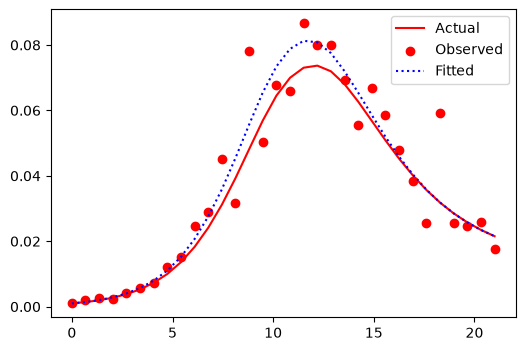

In [415]:
p_bounds = [(1e-6, 25), (1e-6, 5), (1e-6, 50)]

# Find optimal parameters
optimal_result = optimize_parameters(obs_times, observations, SIRS_model, x0, observed_variables=[[1]], p_guess=(2.5, 1, 1/12), known_p=None, p_bounds=p_bounds, tol=1e-12)

#optimal_p = optimal_result.x
optimal_p = optimal_result.x[3:]

print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

# Simulate model with optimal parameters
optimal_model = lambda t, x: SIRS_model(t, x, optimal_p)
optimal_sol = solve_ivp(optimal_model, tspan, x0, method='RK45', t_eval=obs_times)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")
ax.plot(obs_times, optimal_sol.y[1], color='blue', linestyle=":", label="Fitted")

ax.legend()

plt.show()

### Testing parameter and IC optimization

Optimal ICs: [0.9988, 0.0012, 0.    ]
Optimal parameters: [1.43, 0.93, 0.07]


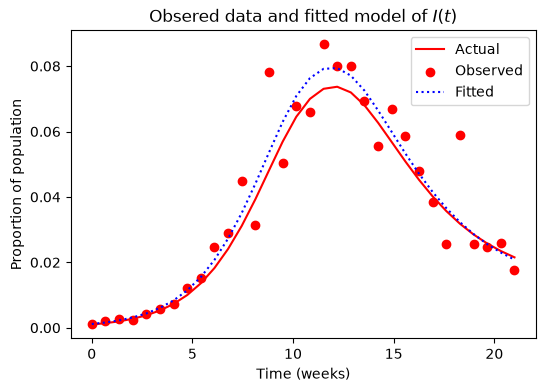

In [416]:
x0_bounds = [(0, 1), (0, 1), (0, 0.1)]

# Find optimal parameters and ICs
optimal_result = optimize_ics_and_parameters(obs_times, observations, SIRS_model,
        observed_variables=[[1]],
        x0_guess=(1 - 10*i0, 10*i0, 0), 
        p_guess=(10, 0.5, 1/6), 
        known_x0=None, known_p=None,
        x0_bounds=x0_bounds, p_bounds=p_bounds, 
        tol=1e-12,
        wiggle_room=1e-8,
)

optimal_x0 = optimal_result.x[:3]
optimal_p = optimal_result.x[3:]

print("Optimal ICs: " + np.array2string(optimal_x0, precision=4, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

# Simulate model with optimal parameters
optimal_model = lambda t, x: SIRS_model(t, x, optimal_p)
optimal_sol = solve_ivp(optimal_model, tspan, optimal_x0, method='RK45', t_eval=obs_times)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(sol.t, sol.y[1], color='red', label="Actual")
ax.scatter(sol.t, observations, color='red', label="Observed")
ax.plot(obs_times, optimal_sol.y[1], color='blue', linestyle=":", label="Fitted")

ax.legend()
ax.set_xlabel("Time (weeks)")
ax.set_ylabel("Proportion of population")

plt.title("Obsered data and fitted model of $I(t)$")

plt.savefig("Figures/SIRS_fitted.pdf", dpi=300)

plt.show()

# Testing model fitting on 1978 English Boarding School Influenza data

Outbreak Dates:['01-22' '01-23' '01-24' '01-25' '01-26' '01-27' '01-28' '01-29' '01-30'
 '01-31' '02-01' '02-02' '02-03' '02-04']
In bed: [  3   8  26  76 225 298 258 233 189 128  68  29  14   4]
Convalescent: [  0   0   0   0   9  17 105 162 176 166 150  85  47  20]
Infected: [  3.   8.  26.  76. 234. 315. 363. 395. 365. 294. 218. 114.  61.  24.]
Optimal x0: [1., 0., 0.]
Optimal parameters: [1.56e+00, 3.45e-01, 1.00e-06]
R0 = 4.52


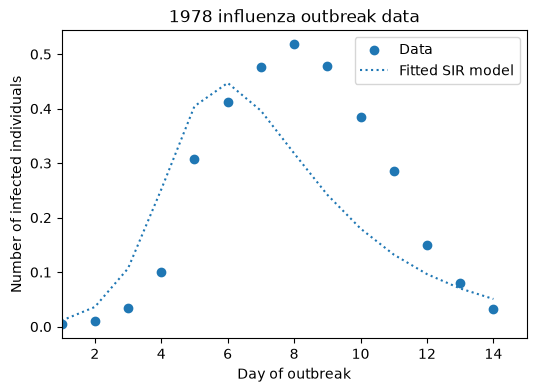

In [417]:
year = 1978
N = 763
observation_days = np.arange(1, 15)
dates = np.array([f"01-{day}" for day in range(22, 32)])
dates = np.concatenate((dates, np.array([f"02-0{day}" for day in range(1, 5)])))

in_bed = np.array([3, 8, 26, 76, 225, 298, 258, 233, 189, 128, 68, 29, 14, 4])
convalescent = np.array([0, 0, 0, 0, 9, 17, 105, 162, 176, 166, 150, 85, 47, 20])
infected = (in_bed + convalescent) / N

print("Outbreak Dates:" + np.array2string(dates))
print("In bed: " + np.array2string(in_bed))
print("Convalescent: " + np.array2string(convalescent))
print("Infected: " + np.array2string(infected * N))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(np.arange(1, 15), infected, label="Data")
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")

ax.set_title("1978 influenza outbreak data")

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, SIRS_model,
        observed_variables=[[1]],
        x0_guess=(N - I0_guess, I0_guess, 0), 
        p_guess=(2.5, 0.1, 0), 
        known_x0=(None, None, 0), known_p=None,
        x0_bounds=x0_bounds, p_bounds=p_bounds, 
        tol=1e-8,
        wiggle_room=1e-12,
)

optimal_x0 = optimal_result.x[:3]
optimal_p = optimal_result.x[3:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: SIRS_model(t, x, optimal_p), (0, 14), optimal_x0, method='RK45', t_eval=observation_days)

ax.plot(observation_days, optimal_sol.y[1], label="Fitted SIR model", linestyle=":")

ax.legend()
ax.set_xlim([1, 15])

print(f"R0 = {(optimal_p[0] / optimal_p[1]):.2f}")

### What if we have two infectious classes?

Optimal x0: [1.  , 0.  , 0.01, 0.1 ]
Optimal parameters: [1.27, 0.65]
R0 = 3.89


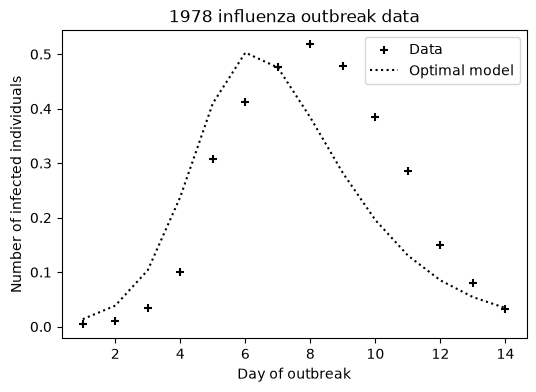

In [418]:
def SIIR_model(t, x, p):
    S, I1, I2, R = x
    β, γ = p

    dS_dt = -β*S*(I1 + I2)
    dI1_dt = β*S*(I1 + I2) - γ*I1
    dI2_dt = γ*I1 - γ*I2
    dR_dt = γ*I2

    return [dS_dt, dI1_dt, dI2_dt, dR_dt]

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, SIIR_model,
        observed_variables = [[1, 2]], # The two I components' sum, x[1] + x[2], should be equal to the observed data
        x0_guess=(N - I0_guess, 0, I0_guess, 0), 
        p_guess=(1, 0.2), 
        known_x0=None, known_p=None,
        x0_bounds=((0, 1), (0, 1), (0, 1e-1), (0, 1e-1)), p_bounds=((0, 50), (1e-2, 1e2)), 
        tol=1e-8,
        wiggle_room=1e-8,
)

optimal_x0 = optimal_result.x[:4]
optimal_p = optimal_result.x[4:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: SIIR_model(t, x, optimal_p), (0, observation_days[-1]), optimal_x0, method='RK45', t_eval=observation_days)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(observation_days, infected, label="Data", marker='+', color='k')
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")
ax.set_title("1978 influenza outbreak data")

ax.plot(observation_days, optimal_sol.y[1] + optimal_sol.y[2], label="Optimal model", color='k', linestyle=':')
ax.legend()

print(f"R0 = {(optimal_p[0] / (optimal_p[1]/2)):.2f}")

plt.savefig("Figures/1978_SIIR_model_fit.pdf", dpi=300)

### Are these parameters (locally) optimal?

Optimal Parameters: [1.27 0.65]
Optimal Loss: 0.9141247893971572


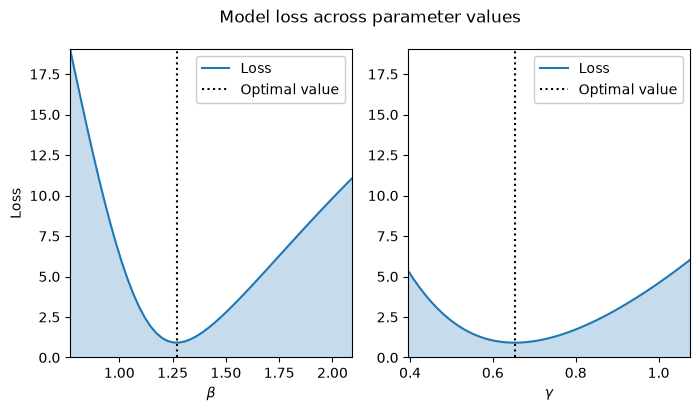

In [419]:
npars = len(optimal_p)
num_par_samples = 50
eps = 0.5
par_distributions = np.zeros((npars, num_par_samples))
losses = np.zeros((npars, num_par_samples))
par_strings = [r"$\beta$", r"$\gamma$"]

print("Optimal Parameters: " + np.array2string(optimal_p, precision=2)) 
print(f"Optimal Loss: {calculate_model_loss(observation_days, infected, SIIR_model, optimal_x0, optimal_p, observed_variables=[[1, 2]])}")

# For each parameter...
for i in range(npars):
    current_pars = optimal_p.copy()
    current_p = current_pars[i]
    par_distributions[i] = np.array([current_p*scale_factor for scale_factor in np.linspace(np.exp(-eps), np.exp(eps), num_par_samples)])
    known_pars = [None for i in range(npars)]

    for j in range(num_par_samples):
        # Perturb it
        current_pars[i] = par_distributions[i,j]
        known_pars[i] = current_pars[i]
        
        # Reoptimize the other parameters (while holding x0 fixed)
        optimal_result = optimize_ics_and_parameters(observation_days, infected, SIIR_model,
                observed_variables = [[1, 2]], # The two I components' sum, x[1] + x[2], should be equal to the observed data
                x0_guess=(N - I0_guess, 0, I0_guess, 0), 
                p_guess=(1, 0.2), 
                known_x0=optimal_x0, known_p=known_pars,
                x0_bounds=None, p_bounds=((0, 50), (1e-2, 1e2)), 
                tol=1e-8,
                wiggle_room=1e-8,
        )

        reoptimized_pars = optimal_result.x[4:]

        # Calculate the loss with the new reoptimized parameters
        losses[i,j] = calculate_model_loss(observation_days, infected, SIIR_model, optimal_x0, reoptimized_pars, observed_variables=[[1, 2]])

fig, axes = plt.subplots(1, npars, figsize=(8,4))

for i in range(npars):
    axes[i].plot(par_distributions[i], losses[i], label="Loss")
    axes[i].fill_between(par_distributions[i], losses[i], alpha=0.25)
    axes[i].plot(np.ones(2)*optimal_p[i], [0, np.max(losses)], label="Optimal value", color='k', linestyle=':')
    axes[i].set_xlabel(par_strings[i])
    axes[i].legend(loc="upper right", framealpha=1)
    axes[i].set_xlim([np.min(par_distributions[i]), np.max(par_distributions[i])])
    axes[i].set_ylim([0, np.max(losses)])

axes[0].set_ylabel("Loss")

fig.suptitle("Model loss across parameter values")

plt.savefig("Figures/1978_SIIR_model_practical_identifiability.pdf", dpi=300)

### Did we find a global optimum? We can perform a global parameter sweep for this simple model.

In [420]:
min_loss = 1e8
losses = np.zeros((num_par_samples, num_par_samples))

for i in range(num_par_samples):
    for j in range(num_par_samples):
        current_pars = optimal_p.copy()
        current_pars[0] = par_distributions[0,i]
        current_pars[1] = par_distributions[1,j]
        # print(current_pars)
        losses[i,j] = calculate_model_loss(observation_days, infected, SIIR_model, optimal_x0, current_pars, observed_variables=[[1, 2]])

        if losses[i,j] <= min_loss:
            min_loss = losses[i,j]
            optimal_p_2 = [current_pars[i] for i in [0, 1]]

print(f"Global Optimal Loss: {np.min(losses)}")

Global Optimal Loss: 0.9243308598641311


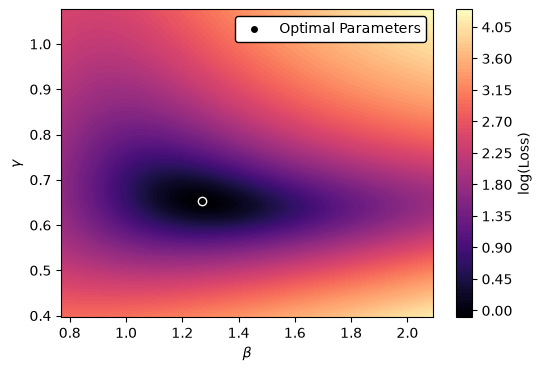

In [421]:
fig, ax = plt.subplots(1, 1, figsize=(6,4))

X, Y = np.meshgrid(par_distributions[0], par_distributions[1])
cf = ax.contourf(X, Y, np.log(losses), levels=100, cmap="magma")

cb = fig.colorbar(cf)
cb.set_label(r"$\log(\mathrm{Loss})$")

ax.scatter([optimal_p[0]], [optimal_p[1]], label="Optimal Parameters", color='k', edgecolor='w')

ax.legend(loc="upper right", framealpha=1, edgecolor='k')

ax.set_xlabel(r"$\beta$")
ax.set_ylabel(r"$\gamma$")

plt.savefig("Figures/1978_SIRS_model_global_loss.png", dpi=300)

### What if we allow for hetergeneous contacts for $I_1$ and $I_2$?

Optimal x0: [9.96e-01, 3.13e-03, 7.88e-04, 1.53e-16]
Optimal parameters: [0.47, 3.53, 0.62, 0.62]
R0 = 0.27


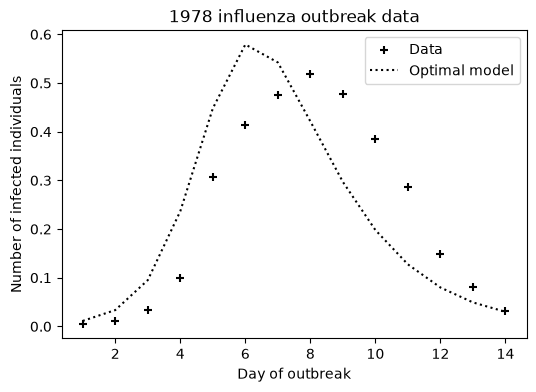

In [422]:
def SIIR_model_heterogeneous(t, x, p):
    S, I1, I2, R = x
    β1, β2, γ1, γ2 = p

    dS_dt = -β1*S*I1 - β2*S*I2
    dI1_dt = β1*S*I1 + β2*S*I2 - γ1*I1
    dI2_dt = γ1*I1 - γ2*I2
    dR_dt = γ2*I2

    return [dS_dt, dI1_dt, dI2_dt, dR_dt]

I0_guess = 1 / N

optimal_result = optimize_ics_and_parameters(observation_days, infected, SIIR_model_heterogeneous,
        observed_variables = [[1, 2]], # The two I components' sum, x[1] + x[2], should be equal to the observed data
        x0_guess=(1 - I0_guess, I0_guess/2, I0_guess/2, 0), 
        p_guess=(1, 1, 0.5, 0.5), 
        known_x0=None, known_p=None,
        x0_bounds=((0, 1), (0, 1e-1), (0, 1e-2), (0, 1e-2)), p_bounds=((0, 5), (0, 5), (1e-1, 1e1), (1e-1, 1e1)), 
        tol=1e-8,
        wiggle_room=1e-4,
)

optimal_x0 = optimal_result.x[:4]
optimal_p = optimal_result.x[4:]

print("Optimal x0: " + np.array2string(optimal_x0, precision=2, separator=', '))
print("Optimal parameters: " + np.array2string(optimal_p, precision=2, separator=', '))

optimal_sol = solve_ivp(lambda t, x: SIIR_model_heterogeneous(t, x, optimal_p), (0, observation_days[-1]), optimal_x0, method='RK45', t_eval=observation_days)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.scatter(observation_days, infected, label="Data", marker='+', color='k')
ax.set_xlabel("Day of outbreak")
ax.set_ylabel("Number of infected individuals")
ax.set_title("1978 influenza outbreak data")

ax.plot(observation_days, optimal_sol.y[1] + optimal_sol.y[2], label="Optimal model", color='k', linestyle=':')
ax.legend()

print(f"R0 = {(optimal_p[0] / (optimal_p[1]/2)):.2f}")

plt.savefig("Figures/1978_SIIR_heterogeneous_model_fit.pdf", dpi=300)

Optimal parameters: [0.47 3.53 0.62 0.62]


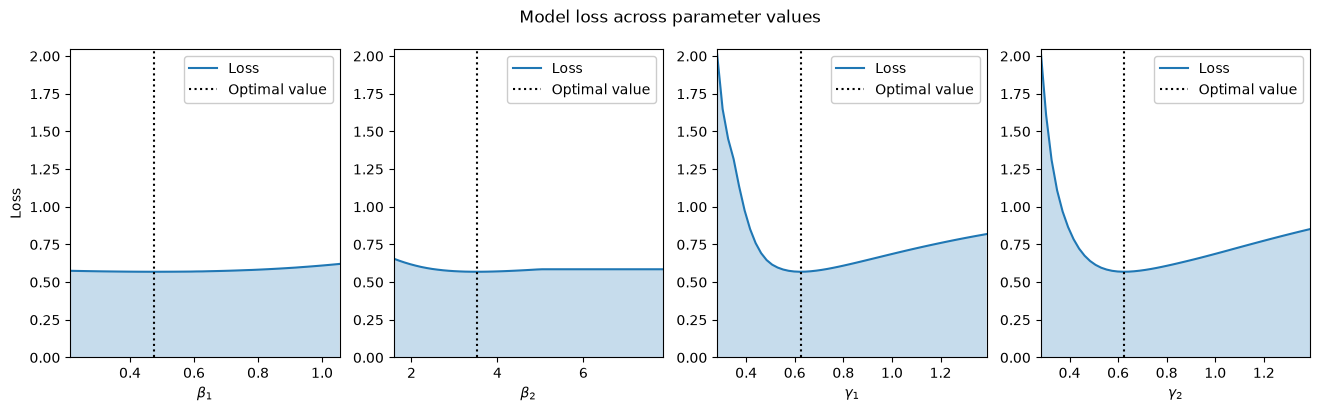

In [423]:
npars = len(optimal_p)
num_par_samples = 50
eps = 0.8
par_distributions = np.zeros((npars, num_par_samples))
losses = np.zeros((npars, num_par_samples))
par_strings = [r"$\beta_1$", r"$\beta_2$", r"$\gamma_1$", r"$\gamma_2$"]

print("Optimal parameters: " + np.array2string(optimal_p, precision=2)) 

for i in range(npars):
    current_pars = optimal_p.copy()
    current_p = current_pars[i]
    par_distributions[i] = np.array([current_p*scale_factor for scale_factor in np.linspace(np.exp(-eps), np.exp(eps), num_par_samples)])
    known_pars = [None for i in range(npars)]
    
    for j in range(num_par_samples):
        # Perturb it
        current_pars[i] = par_distributions[i,j]
        known_pars[i] = current_pars[i]
        
        # Reoptimize the other parameters (while holding x0 fixed)
        optimal_result = optimize_ics_and_parameters(observation_days, infected, SIIR_model_heterogeneous,
                observed_variables = [[1, 2]], # The two I components' sum, x[1] + x[2], should be equal to the observed data
                x0_guess=(1 - I0_guess, I0_guess/2, I0_guess/2, 0), 
                p_guess=(1, 1, 0.2, 0.2), 
                known_x0=optimal_x0, known_p=known_pars,
                x0_bounds=None, p_bounds=((0, 5), (0, 5), (1e-2, 1e2), (1e-2, 1e2)), 
                tol=1e-8,
                wiggle_room=1e-8,
        )

        reoptimized_pars = optimal_result.x[4:]

        # Calculate the loss with the new reoptimized parameters
        losses[i,j] = calculate_model_loss(observation_days, infected, SIIR_model_heterogeneous, optimal_x0, reoptimized_pars, observed_variables=[[1, 2]])

fig, axes = plt.subplots(1, npars, figsize=(16,4))

for i in range(npars):
    axes[i].plot(par_distributions[i], losses[i], label="Loss")
    axes[i].fill_between(par_distributions[i], losses[i], alpha=0.25)
    axes[i].plot(np.ones(2)*optimal_p[i], [0, np.max(losses)], label="Optimal value", color='k', linestyle=':')
    axes[i].set_xlabel(par_strings[i])
    axes[i].legend(loc="upper right", framealpha=1)
    axes[i].set_xlim([np.min(par_distributions[i]), np.max(par_distributions[i])])
    axes[i].set_ylim([0, np.max(losses)])

axes[0].set_ylabel("Loss")

fig.suptitle("Model loss across parameter values")

plt.savefig("Figures/1978_SIIR_heterogeneous_model_practical_identifiability.pdf", dpi=300)